# Mini-Project 1: UBOS District Population Forecaster

All populations are in **thousands of people**. Kampala, Wakiso and Gulu values are the assignment's illustrative series. Kyegegwa and Mubende values below are additional constructed examples, not official UBOS estimates. The forecast comparison uses 2015–2021 as training data and holds out 2022–2024.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.ubos_population import (
    FORECASTER_TYPES,
    DistrictPopulation,
    additional_classrooms,
    bootstrap_prediction_interval,
    compound_annual_growth_rate,
    descriptive_statistics,
    forecast_metrics,
    year_on_year_growth_rates,
)

## Data and input validation

The extra districts are added for comparison only. They should not be cited as measured UBOS estimates.

In [2]:
years = np.arange(2015, 2025)
population_series = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso": [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu": [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Kyegegwa": [270, 285, 300, 315, 330, 345, 360, 375, 390, 405],
    "Mubende": [630, 650, 675, 700, 725, 750, 780, 810, 840, 875],
}
districts = {
    name: DistrictPopulation(name, years, np.asarray(values, dtype=float))
    for name, values in population_series.items()
}
[(name, district, len(district)) for name, district in districts.items()]

[('Kampala',
  DistrictPopulation(name='Kampala', years=10, range=2015-2024),
  10),
 ('Wakiso', DistrictPopulation(name='Wakiso', years=10, range=2015-2024), 10),
 ('Gulu', DistrictPopulation(name='Gulu', years=10, range=2015-2024), 10),
 ('Kyegegwa',
  DistrictPopulation(name='Kyegegwa', years=10, range=2015-2024),
  10),
 ('Mubende',
  DistrictPopulation(name='Mubende', years=10, range=2015-2024),
  10)]

## Descriptive statistics

`statistics.variance` and `statistics.stdev` calculate sample statistics, dividing squared deviations by *n − 1*. NumPy's `var` and `std` default to `ddof=0`, dividing by *n* and treating the observed series as the whole population. Setting `ddof=1` in NumPy applies the sample denominator and aligns its variance/standard deviation with `statistics`.

In [3]:
statistics_table = pd.DataFrame.from_dict(
    {name: descriptive_statistics(district.populations) for name, district in districts.items()},
    orient="index",
)
statistics_table.round(2)

,statistics_mean,statistics_median,statistics_variance,statistics_standard_deviation,numpy_mean,numpy_median,numpy_variance,numpy_standard_deviation
Kampala,1477.0,1460.0,42601.11,206.40,1477.0,1460.0,38341.00,195.81
Wakiso,1280.0,1260.0,60066.67,245.09,1280.0,1260.0,54060.00,232.51
Gulu,389.5,382.5,2885.83,53.72,389.5,382.5,2597.25,50.96
Kyegegwa,337.5,337.5,2062.50,45.41,337.5,337.5,1856.25,43.08
Mubende,743.5,737.5,6772.50,82.30,743.5,737.5,6095.25,78.07


## Growth rates

Annual rates are percentage changes between adjacent observations; CAGR annualizes the first-to-last change across the nine elapsed years.

In [4]:
growth_rows = []
for name, district in districts.items():
    rates = year_on_year_growth_rates(district.populations)
    growth_rows.append({
        "District": name,
        "Mean annual growth (%)": rates.mean(),
        "CAGR (%)": compound_annual_growth_rate(district.years, district.populations),
    })
growth_table = pd.DataFrame(growth_rows).set_index("District")
display(growth_table.round(2))
fastest_growing = growth_table["CAGR (%)"].idxmax()
print(f"Fastest relative growth by CAGR: {fastest_growing} ({growth_table.loc[fastest_growing, 'CAGR (%)']:.2f}% per year)")

,Mean annual growth (%),CAGR (%)
District,,
Kampala,4.61,4.61
Wakiso,6.47,6.47
Gulu,4.61,4.61
Kyegegwa,4.61,4.61
Mubende,3.72,3.72


Fastest relative growth by CAGR: Wakiso (6.47% per year)


## Holdout validation and model selection

Each model is fit only on 2015–2021, then predicts the three held-out years. The selected model for each district is the one with the smallest holdout RMSE; MAE, RMSE and MAPE are all reported in each district's table.

In [5]:
train_mask = years <= 2021
test_mask = years >= 2022
validation_models = {}
validation_tables = {}
selected_types = {}

for name, district in districts.items():
    rows = []
    fitted_models = {}
    for forecaster_type in FORECASTER_TYPES:
        model = forecaster_type().fit(district.years[train_mask], district.populations[train_mask])
        prediction = model.predict(int(test_mask.sum()))
        rows.append({"Model": model.model_name, **forecast_metrics(district.populations[test_mask], prediction)})
        fitted_models[model.model_name] = model
    table = pd.DataFrame(rows).set_index("Model").sort_values("RMSE")
    validation_models[name] = fitted_models
    validation_tables[name] = table
    selected_types[name] = next(
        model_type for model_type in FORECASTER_TYPES
        if model_type().model_name == table.index[0]
    )
    print(f"{name} — selected: {table.index[0]}")
    display(table.round(2))

Kampala — selected: Exponential/CAGR


,MAE,RMSE,MAPE
Model,,,
Exponential/CAGR,9.62,10.39,0.55
Linear trend,37.62,38.97,2.17
Fibonacci ratio,3543.33,4025.36,202.00


Wakiso — selected: Exponential/CAGR


,MAE,RMSE,MAPE
Model,,,
Exponential/CAGR,6.8,8.05,0.42
Linear trend,49.4,52.37,3.09
Fibonacci ratio,3060.0,3479.87,189.87


Gulu — selected: Exponential/CAGR


,MAE,RMSE,MAPE
Model,,,
Exponential/CAGR,9.44,10.87,2.02
Linear trend,18.57,20.29,4.01
Fibonacci ratio,911.67,1035.64,196.04


Kyegegwa — selected: Linear trend


,MAE,RMSE,MAPE
Model,,,
Linear trend,0.00,0.00,0.00
Exponential/CAGR,6.53,7.31,1.65
Fibonacci ratio,810.00,920.35,204.46


Mubende — selected: Exponential/CAGR


,MAE,RMSE,MAPE
Model,,,
Exponential/CAGR,3.76,4.45,0.44
Linear trend,15.24,16.46,1.79
Fibonacci ratio,1758.33,1996.92,205.63


## 2025–2029 forecasts, residual-bootstrap intervals and classroom planning

The selected model is refit to all ten observations before producing the five-year projection. Prediction intervals resample in-sample residuals 1,000 times using a fixed seed. Classroom estimates assume that current capacity already meets 2024 demand; the forecast need is rounded up to whole rooms and compared with the similarly rounded 2024 need.

In [6]:
future_years = np.arange(2025, 2030)
forecasts = {}
planning_rows = []
variance_rows = []

for name, district in districts.items():
    model_type = selected_types[name]
    point, lower, upper = bootstrap_prediction_interval(
        model_type, district.years, district.populations, len(future_years),
        resamples=1_000, confidence=0.95, seed=2026,
    )
    model = model_type().fit(district.years, district.populations)
    forecasts[name] = {"model": model, "point": point, "lower": lower, "upper": upper}
    planning_rows.append({
        "District": name,
        "Selected model": model_type.model_name,
        "2029 forecast (thousands)": point[-1],
        "2029 95% lower": lower[-1],
        "2029 95% upper": upper[-1],
        "Additional classrooms by 2029": additional_classrooms(district.populations[-1], point[-1]),
    })
    variance_rows.append({
        "District": name,
        "Actual variance (2015–2024)": np.var(district.populations),
        "Forecast variance (2025–2029)": np.var(point),
    })

planning_table = pd.DataFrame(planning_rows).set_index("District")
display(planning_table.round(2))
variance_table = pd.DataFrame(variance_rows).set_index("District")
display(variance_table.round(2))
lower_variance = variance_table["Forecast variance (2025–2029)"] < variance_table["Actual variance (2015–2024)"]
print(f"Forecast variance is lower than historical variance for all districts: {bool(lower_variance.all())}.")

,Selected model,2029 forecast (thousands),2029 95% lower,2029 95% upper,Additional classrooms by 2029
District,,,,,
Kampala,Exponential/CAGR,2254.76,2231.11,2262.32,1544
Wakiso,Exponential/CAGR,2284.67,2273.22,2291.43,2088
Gulu,Exponential/CAGR,601.27,590.42,601.27,412
Kyegegwa,Linear trend,480.00,480.00,480.00,255
Mubende,Exponential/CAGR,1050.19,1044.05,1050.19,595


,Actual variance (2015–2024),Forecast variance (2025–2029)
District,,
Kampala,38341.00,17286.15
Wakiso,54060.00,32105.09
Gulu,2597.25,1229.24
Kyegegwa,1856.25,450.00
Mubende,6095.25,2544.56


Forecast variance is lower than historical variance for all districts: True.


A forecast variance below the historical variance indicates a smoother projected path, not necessarily more certainty. A larger value indicates more spread in the five projected annual values. These variances cover different windows (ten observed years versus five forecast years), so they are descriptive rather than a like-for-like uncertainty comparison.

## Actual, fitted, holdout and forecast plots

The vertical line marks the training/test boundary. The selected holdout model's fitted training values and 2022–2024 predictions are shown separately from the final model refit and forecast.

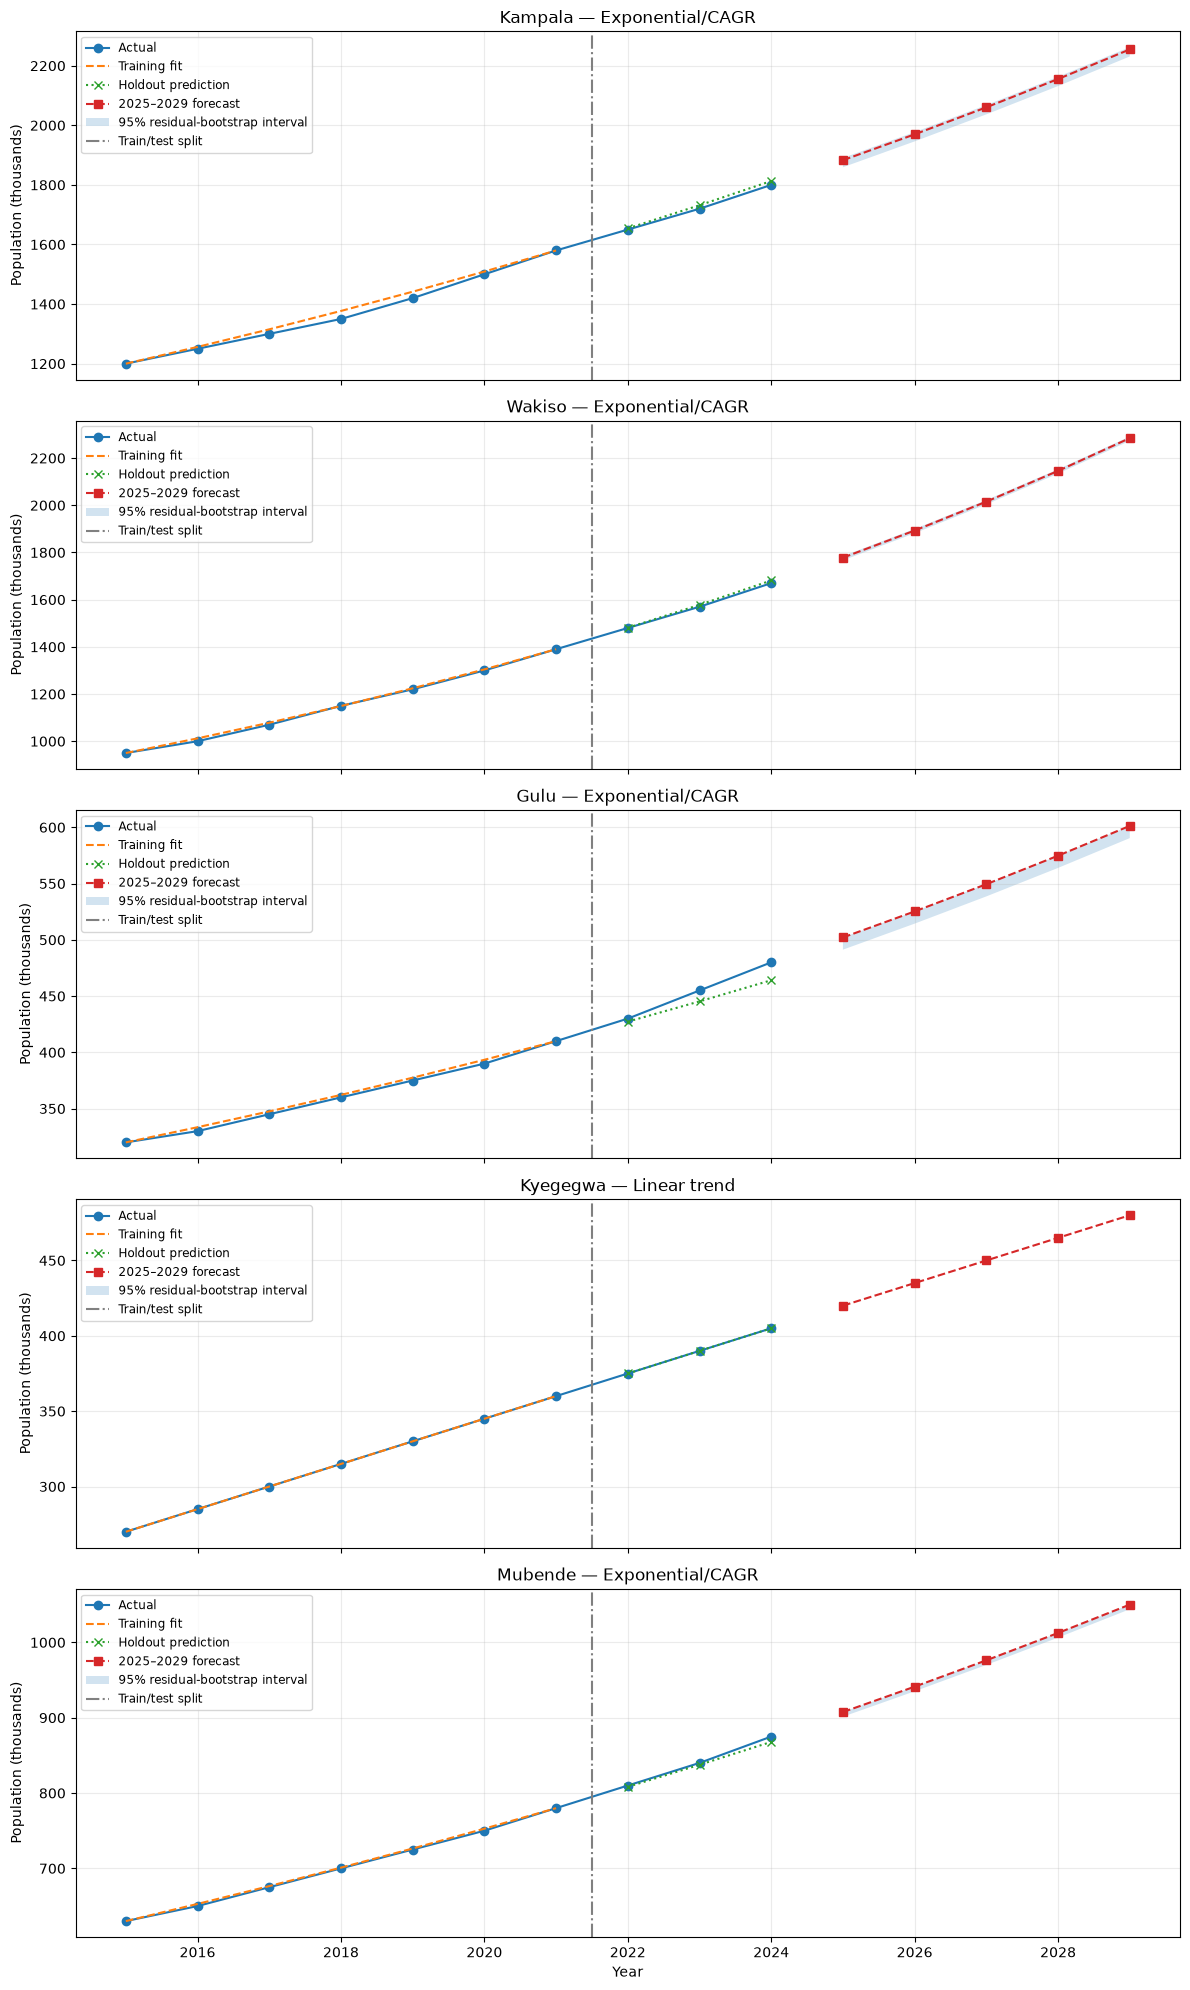

In [7]:
fig, axes = plt.subplots(len(districts), 1, figsize=(12, 4 * len(districts)), sharex=True)
for ax, (name, district) in zip(axes, districts.items()):
    selected_name = selected_types[name].model_name
    validation_model = validation_models[name][selected_name]
    validation_prediction = validation_model.predict(int(test_mask.sum()))
    final = forecasts[name]
    ax.plot(district.years, district.populations, marker="o", label="Actual")
    ax.plot(district.years[train_mask], validation_model.fitted_values, linestyle="--", label="Training fit")
    ax.plot(district.years[test_mask], validation_prediction, marker="x", linestyle=":", label="Holdout prediction")
    ax.plot(future_years, final["point"], marker="s", linestyle="--", label="2025–2029 forecast")
    ax.fill_between(future_years, final["lower"], final["upper"], alpha=0.2, label="95% residual-bootstrap interval")
    ax.axvline(2021.5, color="grey", linestyle="-.", label="Train/test split")
    ax.set_title(f"{name} — {selected_name}")
    ax.set_ylabel("Population (thousands)")
    ax.grid(alpha=0.25)
    ax.legend(loc="best", fontsize="small")
axes[-1].set_xlabel("Year")
fig.tight_layout()
plt.show()

## Findings & Limitations

The five districts all show increasing population across the supplied decade, although their relative growth rates differ; the CAGR table identifies the fastest-growing district by percentage rather than absolute population added. The holdout tables provide a fairer model comparison than in-sample fit because every method predicts the same three unseen years. The selected model can differ by district, and a low error on this short holdout should not be interpreted as proof that the same process will persist through 2029. Linear trend assumes a constant absolute annual increase, while exponential/CAGR assumes a constant proportional increase. Both simplify migration, boundary changes, fertility, mortality and shocks.

The Fibonacci-ratio forecast multiplies each successive value by Fibonacci ratios that approach the golden ratio. That implies sustained growth near 62% per year and is not defensible for long-run district population planning absent extraordinary, explicitly justified growth conditions. It is retained as a required comparison, not a recommendation. Bootstrap intervals reuse empirical in-sample residuals independently across forecast years; they do not capture model selection, parameter uncertainty, serial dependence or changing demographic conditions. Kyegegwa and Mubende inputs are constructed illustrative examples, so their outputs are demonstrations only. The classroom calculation assumes the 2024 school-age population is already accommodated, a constant 18% school-age share and 53 pupils per room; it estimates incremental rooms, not staffing, construction timing, costs or geographic distribution. Historical and forecast variances use unequal time windows and are descriptive only.

# References

- Course assignment prompt and supplied Kampala, Wakiso and Gulu illustrative population series.
- NumPy documentation: [`numpy.var`](https://numpy.org/doc/stable/reference/generated/numpy.var.html), [`numpy.std`](https://numpy.org/doc/stable/reference/generated/numpy.std.html), [`numpy.polyfit`](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html), and [`numpy.random.default_rng`](https://numpy.org/doc/stable/reference/random/generator.html).
- Python documentation: [`statistics`](https://docs.python.org/3/library/statistics.html).
- Kyegegwa and Mubende series are constructed illustrative examples, not official UBOS data; their values are not sourced from an external dataset.